In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.optim.lr_scheduler import ReduceLROnPlateau

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available()
                      else 'cpu')
print(f'Using device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Using device: mps


In [2]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

# Training: random crop + flip (Section 4.1 of the paper)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Test: just normalize, no augmentation
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,  download=True, transform=train_transform)
test_dataset  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2)
test_loader  = torch.utils.data.DataLoader(test_dataset,  batch_size=128, shuffle=False, num_workers=2)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
CLASS_EMOJI = ['✈️', '🚗', '🐦', '🐱', '🦌', '🐶', '🐸', '🐴', '🚢', '🚚']

print(f'Training images : {len(train_dataset):,}')
print(f'Test images     : {len(test_dataset):,}')
print(f'Classes         : {CLASS_NAMES}')

Training images : 50,000
Test images     : 10,000
Classes         : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


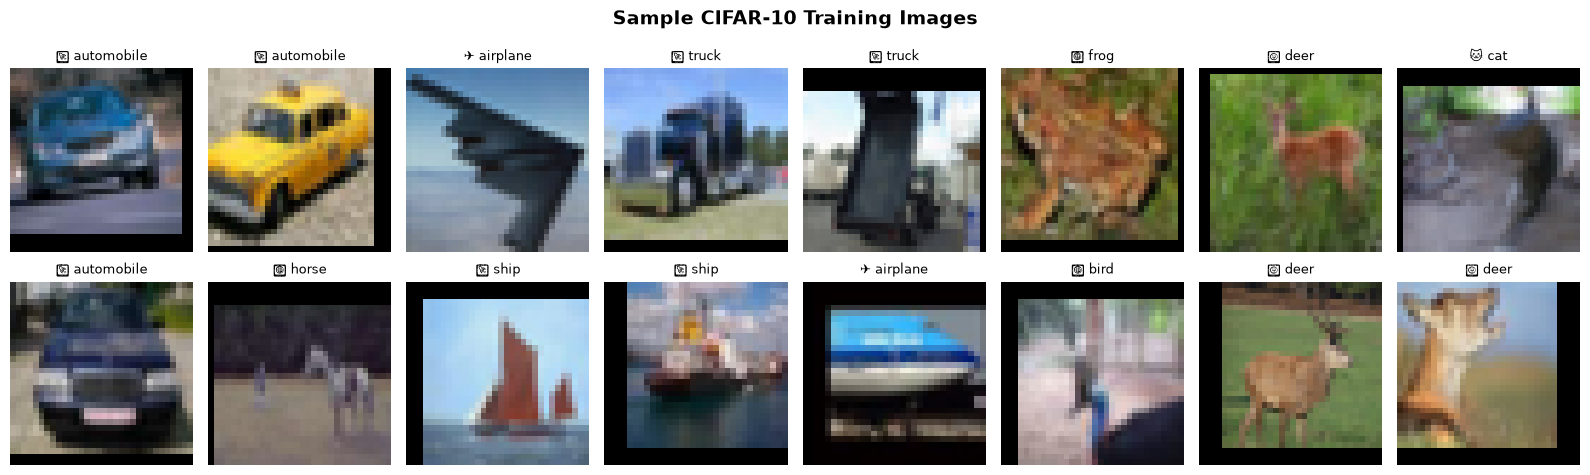

In [3]:
def denormalize(tensor):
    mean = torch.tensor(CIFAR10_MEAN).view(3,1,1)
    std  = torch.tensor(CIFAR10_STD).view(3,1,1)
    return (tensor * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle('Sample CIFAR-10 Training Images', fontsize=14, fontweight='bold')
indices = np.random.choice(len(train_dataset), 16, replace=False)
for ax, idx in zip(axes.flat, indices):
    img, label = train_dataset[idx]
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(f'{CLASS_EMOJI[label]} {CLASS_NAMES[label]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
class MiniAlexNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Conv1
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            # Conv2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            # Conv3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Conv4
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Conv5
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        # Figure out the flattened size automatically
        # instead of hardcoding it
        self._flat_size = self._get_flat_size()

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(self._flat_size, 1024),
            nn.ReLU(inplace=True),

            nn.Dropout(p=0.5),
            nn.Linear(1024, 512),
            nn.ReLU(inplace=True),

            nn.Linear(512, num_classes),
        )

    def _get_flat_size(self):
        """Pass a dummy tensor through features to get the correct flattened size."""
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 32, 32)
            out = self.features(dummy)
            return out.view(1, -1).shape[1]

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


model = MiniAlexNet(num_classes=10).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Flattened size after conv layers: {model._flat_size}')
print(f'Parameters: {total_params:,}  (original AlexNet: ~60,000,000)')
print(model)

Flattened size after conv layers: 1152
Parameters: 2,966,538  (original AlexNet: ~60,000,000)
MiniAlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_f

In [5]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

print('Ready to train.')

Ready to train.


In [6]:
NUM_EPOCHS = 15
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if training:
                optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

print(f'{"Epoch":>6} | {"Train Loss":>10} | {"Train Acc":>9} | {"Val Loss":>8} | {"Val Acc":>8} | {"LR":>8}')
print('-' * 65)

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss,   val_acc   = run_epoch(test_loader,  training=False)
    scheduler.step(val_loss)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    lr = optimizer.param_groups[0]['lr']
    print(f'{epoch:>6} | {train_loss:>10.4f} | {train_acc:>8.2f}% | {val_loss:>8.4f} | {val_acc:>7.2f}% | {lr:>8.6f}')

print(f'\nBest val accuracy: {max(history["val_acc"]):.2f}%')

 Epoch | Train Loss | Train Acc | Val Loss |  Val Acc |       LR
-----------------------------------------------------------------
     1 |     2.2419 |    13.36% |   1.9515 |   24.03% | 0.010000
     2 |     1.8126 |    30.04% |   1.5476 |   41.32% | 0.010000
     3 |     1.5542 |    40.71% |   1.3621 |   47.63% | 0.010000
     4 |     1.3441 |    50.33% |   1.1654 |   58.21% | 0.010000
     5 |     1.1746 |    57.72% |   1.0512 |   63.08% | 0.010000
     6 |     1.0350 |    63.20% |   0.9099 |   67.96% | 0.010000
     7 |     0.9327 |    66.80% |   0.9314 |   67.71% | 0.010000
     8 |     0.8578 |    70.03% |   0.7650 |   73.69% | 0.010000
     9 |     0.7889 |    72.67% |   0.8040 |   73.17% | 0.010000
    10 |     0.7365 |    74.65% |   0.6848 |   76.65% | 0.010000
    11 |     0.6979 |    75.97% |   0.6445 |   78.09% | 0.010000
    12 |     0.6464 |    77.97% |   0.6527 |   77.81% | 0.010000
    13 |     0.6048 |    79.19% |   0.6001 |   79.63% | 0.010000
    14 |     0.5793 |   

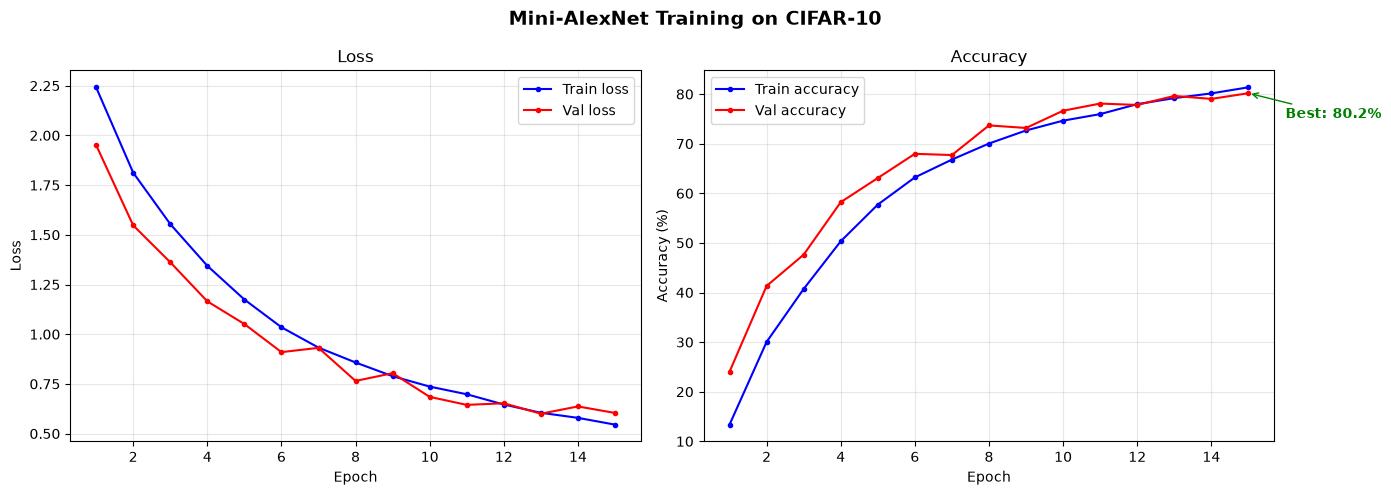

Train/val accuracy gap: 1.2% ✅ looks healthy


In [7]:
epochs = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Mini-AlexNet Training on CIFAR-10', fontsize=14, fontweight='bold')

ax1.plot(epochs, history['train_loss'], 'b-o', markersize=3, label='Train loss')
ax1.plot(epochs, history['val_loss'],   'r-o', markersize=3, label='Val loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title('Loss')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(epochs, history['train_acc'], 'b-o', markersize=3, label='Train accuracy')
ax2.plot(epochs, history['val_acc'],   'r-o', markersize=3, label='Val accuracy')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title('Accuracy')
ax2.legend(); ax2.grid(True, alpha=0.3)

best_epoch = np.argmax(history['val_acc']) + 1
best_acc   = max(history['val_acc'])
ax2.annotate(f'Best: {best_acc:.1f}%',
             xy=(best_epoch, best_acc), xytext=(best_epoch+1, best_acc-5),
             arrowprops=dict(arrowstyle='->', color='green'),
             color='green', fontweight='bold')

plt.tight_layout(); plt.show()

gap = history['train_acc'][-1] - history['val_acc'][-1]
print(f'Train/val accuracy gap: {gap:.1f}%', end=' ')
print('⚠️ overfitting' if gap > 15 else '✅ looks healthy')

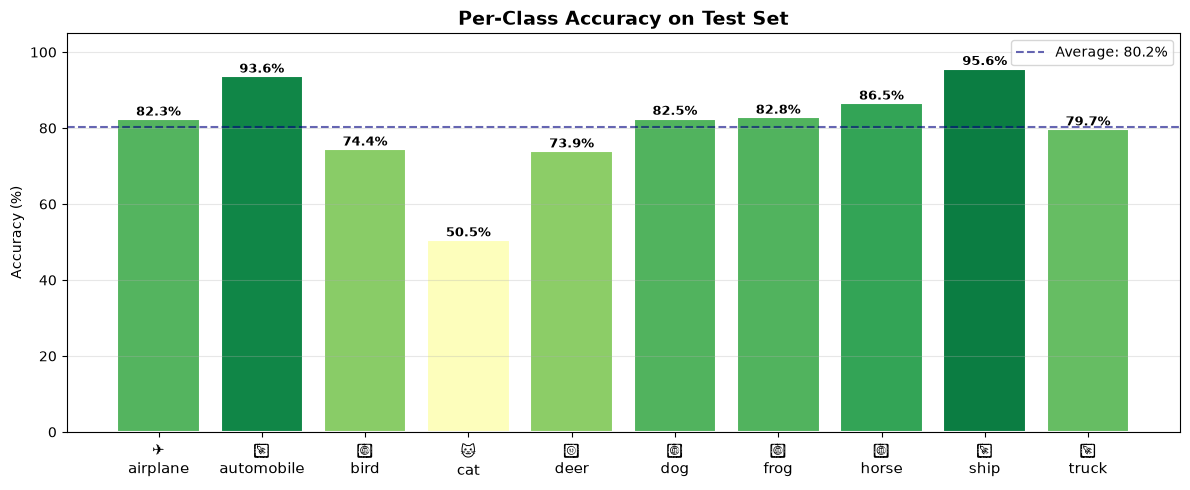


Per-class breakdown:
  ✈️ airplane    :  82.3%  ████████████████
  🚗 automobile  :  93.6%  ██████████████████
  🐦 bird        :  74.4%  ██████████████
  🐱 cat         :  50.5%  ██████████
  🦌 deer        :  73.9%  ██████████████
  🐶 dog         :  82.5%  ████████████████
  🐸 frog        :  82.8%  ████████████████
  🐴 horse       :  86.5%  █████████████████
  🚢 ship        :  95.6%  ███████████████████
  🚚 truck       :  79.7%  ███████████████


In [8]:
model.eval()
class_correct = [0] * 10
class_total   = [0] * 10

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        _, predicted = model(inputs).max(1)
        for label, pred in zip(labels, predicted):
            class_correct[label] += (label == pred).item()
            class_total[label]   += 1

class_acc = [100.0 * class_correct[i] / class_total[i] for i in range(10)]

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.RdYlGn([a / 100 for a in class_acc])
bars = ax.bar(range(10), class_acc, color=colors, edgecolor='white', linewidth=1.5)
ax.set_xticks(range(10))
ax.set_xticklabels([f'{CLASS_EMOJI[i]}\n{CLASS_NAMES[i]}' for i in range(10)], fontsize=11)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Per-Class Accuracy on Test Set', fontsize=14, fontweight='bold')
ax.set_ylim(0, 105)
ax.axhline(sum(class_acc)/10, color='navy', linestyle='--', alpha=0.6,
           label=f'Average: {sum(class_acc)/10:.1f}%')
ax.legend(); ax.grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            f'{acc:.1f}%', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.show()

print('\nPer-class breakdown:')
for i in range(10):
    bar = '█' * int(class_acc[i] / 5)
    print(f'  {CLASS_EMOJI[i]} {CLASS_NAMES[i]:12s}: {class_acc[i]:5.1f}%  {bar}')

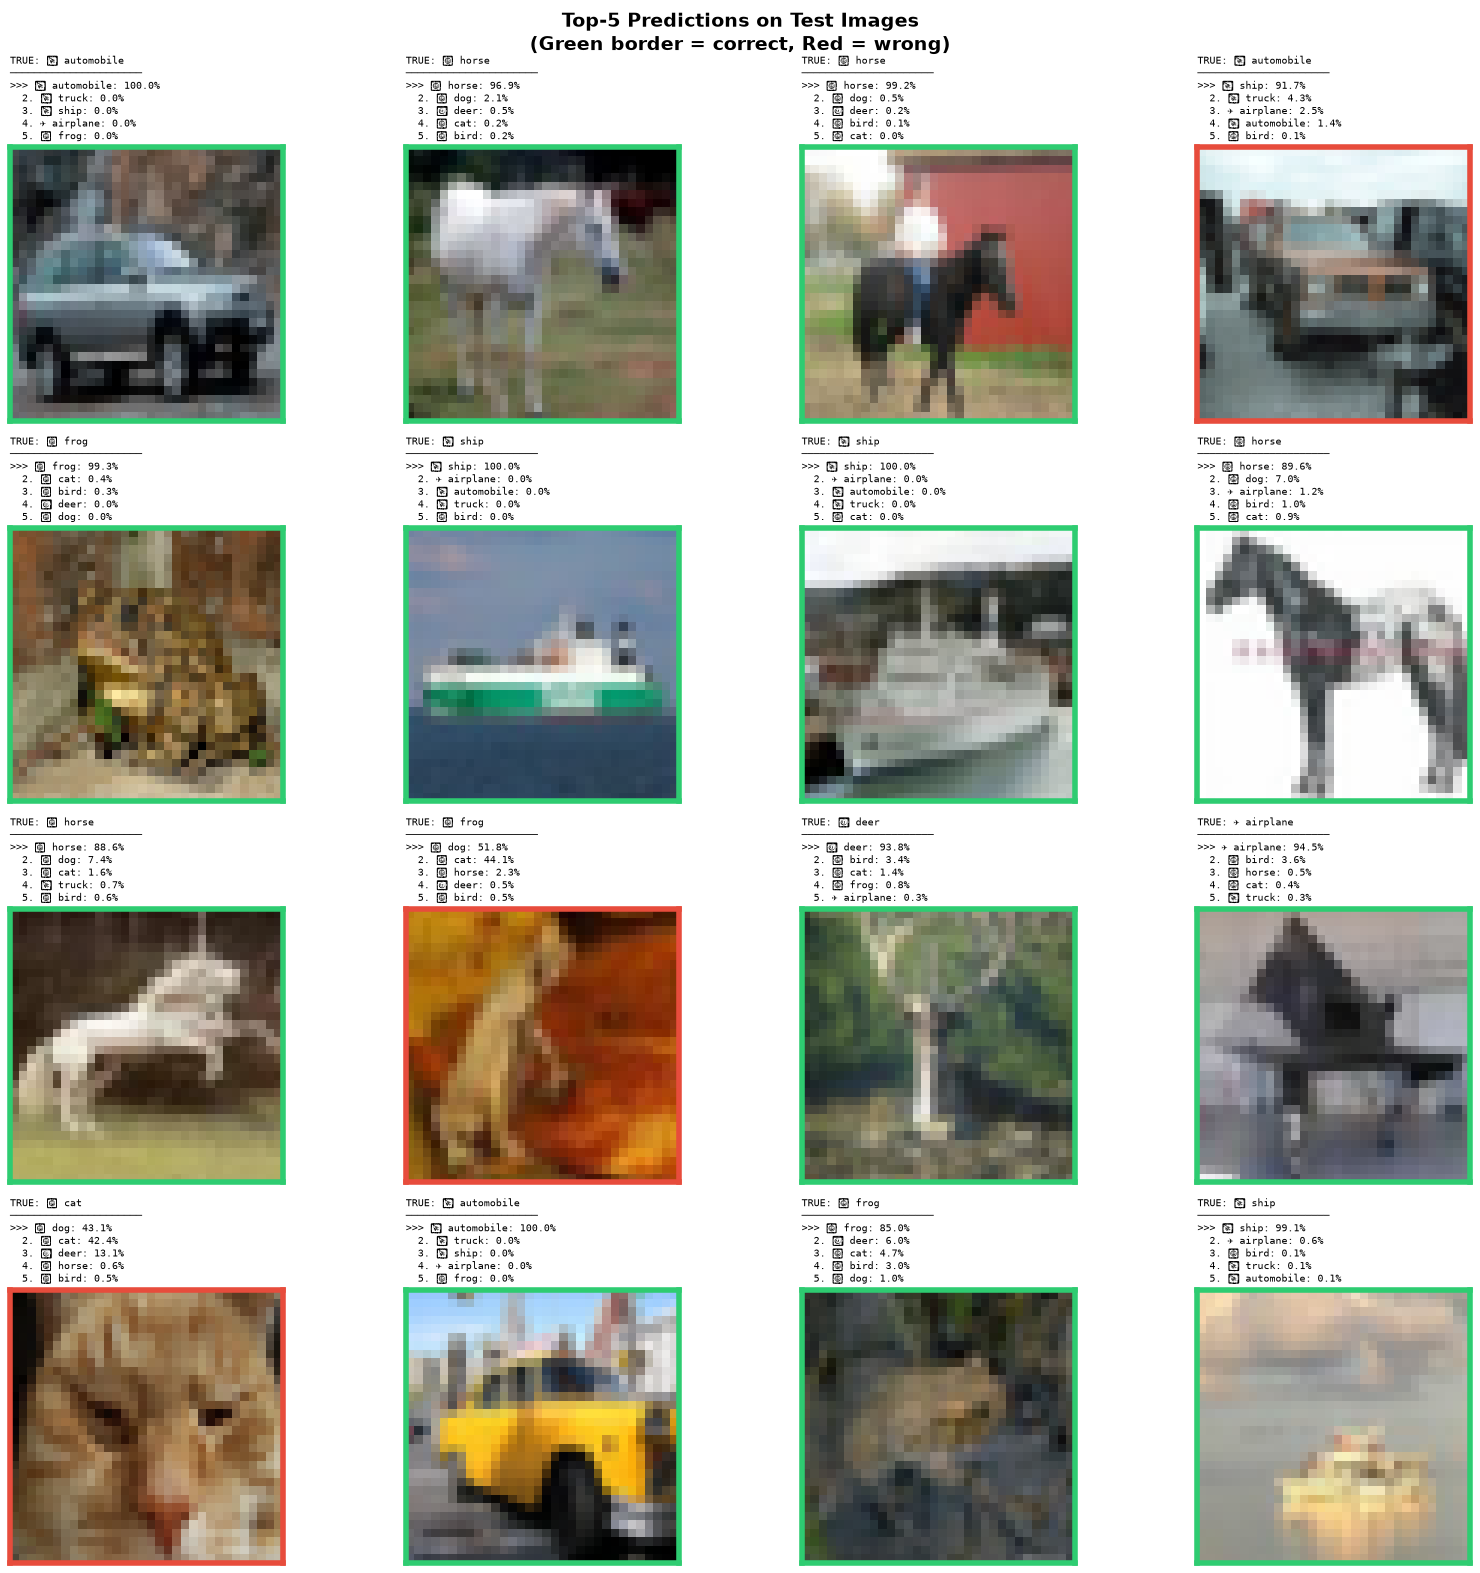

In [9]:
model.eval()
indices = np.random.choice(len(test_dataset), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
fig.suptitle('Top-5 Predictions on Test Images\n(Green border = correct, Red = wrong)',
             fontsize=14, fontweight='bold')

with torch.no_grad():
    for ax, idx in zip(axes.flat, indices):
        img_tensor, true_label = test_dataset[idx]
        output = model(img_tensor.unsqueeze(0).to(device))
        probs  = torch.softmax(output, dim=1).squeeze().cpu().numpy()
        top5_idx  = probs.argsort()[::-1][:5]
        top5_prob = probs[top5_idx]
        correct   = (top5_idx[0] == true_label)

        ax.imshow(denormalize(img_tensor).permute(1, 2, 0))
        border_color = '#2ecc71' if correct else '#e74c3c'
        for spine in ax.spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(4)

        lines = [f'TRUE: {CLASS_EMOJI[true_label]} {CLASS_NAMES[true_label]}', '─'*22]
        for rank, (ci, prob) in enumerate(zip(top5_idx, top5_prob)):
            marker = '>>>' if rank == 0 else f'  {rank+1}.'
            lines.append(f'{marker} {CLASS_EMOJI[ci]} {CLASS_NAMES[ci]}: {prob*100:.1f}%')

        ax.set_title('\n'.join(lines), fontsize=7.5, loc='left',
                     fontfamily='monospace')
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout(); plt.show()

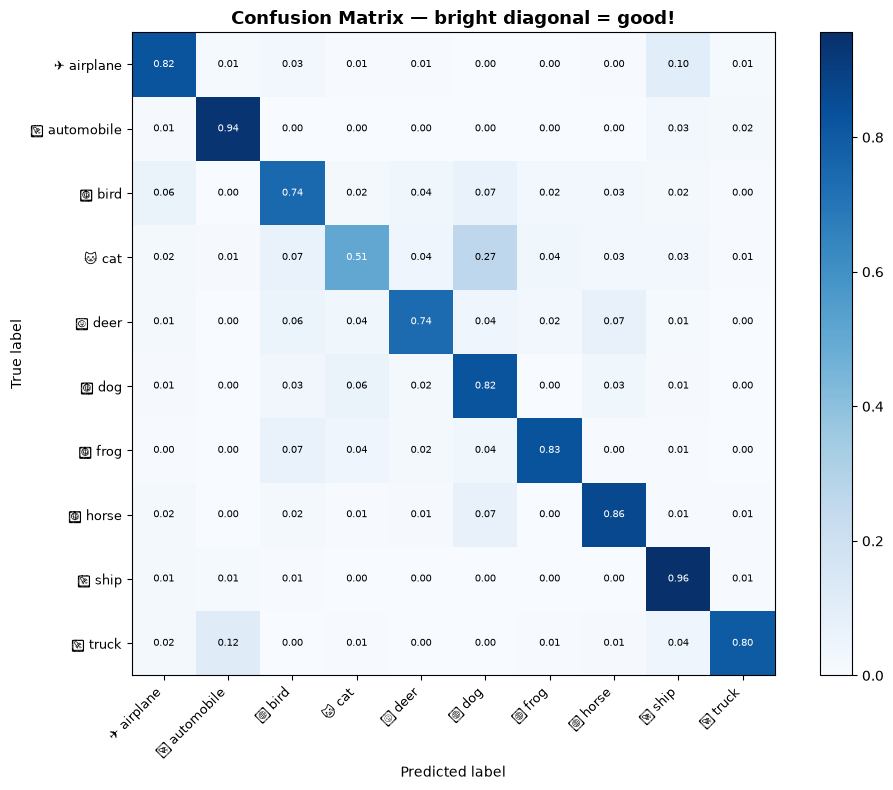


Top confusions:
  🐱 cat          mistaken for 🐶 dog          (265x)
  🚚 truck        mistaken for 🚗 automobile   (115x)
  ✈️ airplane     mistaken for 🚢 ship         (102x)
  🦌 deer         mistaken for 🐴 horse        (74x)
  🐴 horse        mistaken for 🐶 dog          (73x)


In [10]:
from sklearn.metrics import confusion_matrix
import itertools

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        _, predicted = model(inputs.to(device)).max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm_norm, cmap='Blues')
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Confusion Matrix — bright diagonal = good!', fontsize=13, fontweight='bold')
tick_labels = [f'{CLASS_EMOJI[i]} {CLASS_NAMES[i]}' for i in range(10)]
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel('True label'); ax.set_xlabel('Predicted label')
thresh = cm_norm.max() / 2
for i, j in itertools.product(range(10), range(10)):
    ax.text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center', fontsize=7,
            color='white' if cm_norm[i,j] > thresh else 'black')
plt.tight_layout(); plt.show()

print('\nTop confusions:')
off_diag = [(cm[i,j], i, j) for i in range(10) for j in range(10) if i != j]
for count, true, pred in sorted(off_diag, reverse=True)[:5]:
    print(f'  {CLASS_EMOJI[true]} {CLASS_NAMES[true]:12s} mistaken for {CLASS_EMOJI[pred]} {CLASS_NAMES[pred]:12s} ({count}x)')